In [1]:
import pandas as pd

df_raw = pd.read_excel("Online Retail.xlsx")

df_raw.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
print("Jumlah baris:", df_raw.shape[0])
print("Jumlah kolom:", df_raw.shape[1])

df_raw.info()

Jumlah baris: 541909
Jumlah kolom: 8
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [3]:
missing_summary = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct": df_raw.isna().mean() * 100
})

missing_summary.sort_values(
    "missing_count", ascending=False
).round(2)

,missing_count,missing_pct
CustomerID,135080,24.93
Description,1454,0.27
InvoiceNo,0,0.00
StockCode,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


In [4]:
duplicate_count = df_raw.duplicated().sum()

print("Jumlah baris duplikat:", duplicate_count)
print(
    "Persentase duplikat:",
    round(duplicate_count / len(df_raw) * 100, 2),
    "%"
)

df_raw[df_raw.duplicated(keep=False)].head(10)

Jumlah baris duplikat: 5268
Persentase duplikat: 0.97 %


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [5]:
cancelled = (
    df_raw["InvoiceNo"]
    .astype("string")
    .str.upper()
    .str.startswith("C", na=False)
)

nonpositive_quantity = df_raw["Quantity"] <= 0
nonpositive_price = df_raw["UnitPrice"] <= 0

issue_summary = pd.Series({
    "Invoice pembatalan (jumlah baris)": cancelled.sum(),
    "Quantity <= 0": nonpositive_quantity.sum(),
    "UnitPrice <= 0": nonpositive_price.sum()
})

issue_summary

Invoice pembatalan (jumlah baris)     9288
Quantity <= 0                        10624
UnitPrice <= 0                        2517
dtype: int64

In [6]:
df_raw.loc[
    cancelled | nonpositive_quantity | nonpositive_price,
    [
        "CustomerID",
        "InvoiceNo",
        "Quantity",
        "UnitPrice",
        "Description"
    ]
].head(15)

,CustomerID,InvoiceNo,Quantity,UnitPrice,Description
141,14527.0,C536379,-1,27.50,Discount
154,15311.0,C536383,-1,4.65,SET OF 3 COLOURED FLYING DUCKS
235,17548.0,C536391,-12,1.65,PLASTERS IN TIN CIRCUS PARADE
236,17548.0,C536391,-24,0.29,PACK OF 12 PINK PAISLEY TISSUES
237,17548.0,C536391,-24,0.29,PACK OF 12 BLUE PAISLEY TISSUES
238,17548.0,C536391,-24,0.29,PACK OF 12 RED RETROSPOT TISSUES
239,17548.0,C536391,-12,3.45,CHICK GREY HOT WATER BOTTLE
240,17548.0,C536391,-12,1.65,PLASTERS IN TIN VINTAGE PAISLEY
241,17548.0,C536391,-24,1.65,PLASTERS IN TIN SKULLS
622,NaN,536414,56,0.00,NaN


In [7]:
parsed_dates = pd.to_datetime(
    df_raw["InvoiceDate"],
    errors="coerce"
)

failed_dates = (
    df_raw["InvoiceDate"].notna()
    & parsed_dates.isna()
)

print("Tanggal kosong:", df_raw["InvoiceDate"].isna().sum())
print("Tanggal gagal dikonversi:", failed_dates.sum())
print("Tanggal paling awal:", parsed_dates.min())
print("Tanggal paling akhir:", parsed_dates.max())

Tanggal kosong: 0
Tanggal gagal dikonversi: 0
Tanggal paling awal: 2010-12-01 08:26:00
Tanggal paling akhir: 2011-12-09 12:50:00


In [8]:
df = df_raw.copy()

cleaning_log = [{
    "step": "Data awal",
    "rows_remaining": len(df),
    "rows_removed": 0
}]

In [9]:
before = len(df)

df = df.dropna(subset=["CustomerID"]).copy()

cleaning_log.append({
    "step": "Hapus CustomerID kosong",
    "rows_remaining": len(df),
    "rows_removed": before - len(df)
})

In [10]:
before = len(df)

df = df.drop_duplicates().copy()

cleaning_log.append({
    "step": "Hapus duplikat identik",
    "rows_remaining": len(df),
    "rows_removed": before - len(df)
})

In [11]:
before = len(df)

is_cancelled = (
    df["InvoiceNo"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.startswith("C", na=False)
)

valid_purchase = (
    ~is_cancelled
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
)

df = df.loc[valid_purchase].copy()

cleaning_log.append({
    "step": "Keluarkan pembatalan dan quantity/harga <= 0",
    "rows_remaining": len(df),
    "rows_removed": before - len(df)
})

In [12]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="raise"
)

df["CustomerID"] = (
    df["CustomerID"]
    .astype("int64")
    .astype("string")
)

df["InvoiceNo"] = df["InvoiceNo"].astype("string").str.strip()

df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

In [13]:
cleaning_report = pd.DataFrame(cleaning_log)

cleaning_report

,step,rows_remaining,rows_removed
0,Data awal,541909,0
1,Hapus CustomerID kosong,406829,135080
2,Hapus duplikat identik,401604,5225
3,Keluarkan pembatalan dan quantity/harga <= 0,392692,8912


In [14]:
assert df["CustomerID"].notna().all()
assert not df.duplicated().any()
assert df["Quantity"].gt(0).all()
assert df["UnitPrice"].gt(0).all()
assert df["InvoiceDate"].notna().all()
assert not df["InvoiceNo"].str.upper().str.startswith("C").any()

print("Semua pemeriksaan cleaning lolos.")
print("Baris tersisa:", len(df))
print("Description masih kosong:", df["Description"].isna().sum())

df[
    [
        "CustomerID",
        "InvoiceNo",
        "InvoiceDate",
        "Quantity",
        "UnitPrice",
        "TotalPrice"
    ]
].head()

Semua pemeriksaan cleaning lolos.
Baris tersisa: 392692
Description masih kosong: 0


,CustomerID,InvoiceNo,InvoiceDate,Quantity,UnitPrice,TotalPrice
0,17850,536365,2010-12-01 08:26:00,6,2.55,15.30
1,17850,536365,2010-12-01 08:26:00,6,3.39,20.34
2,17850,536365,2010-12-01 08:26:00,8,2.75,22.00
3,17850,536365,2010-12-01 08:26:00,6,3.39,20.34
4,17850,536365,2010-12-01 08:26:00,6,3.39,20.34


## Exploratory Data Analysis

### Objective

This analysis explores purchasing activity, customer spending, and the concentration of purchase value before building customer segments using RFM and K-Means.

The analysis addresses the following questions:

- How many customers and transactions are represented in the cleaned dataset?
- What is the total purchase value during the observation period?
- How much does a customer spend on average, and how does this differ from the average order value?
- Which customers contribute the most purchase value?
- How does spending vary across customers?

### Analysis Scope

The cleaned dataset contains **392,692 purchase line items** with identified customers, positive quantities, and positive unit prices. Exact duplicate rows and invoices marked as cancellations have been excluded.

Purchase value is calculated as `Quantity × UnitPrice` and reported in GBP. It represents positive purchases in the cleaned dataset before deducting returns, rather than net revenue.

Transactions without a CustomerID are excluded. Therefore, the findings describe identified customers represented in the cleaned data, rather than all transactions in the original dataset.

### Key Metrics

| Metric | Definition |
|---|---|
| Total Customers | Number of unique customers in the cleaned dataset |
| Total Transactions | Number of unique invoices in the cleaned dataset |
| Total Purchase Value | Sum of purchase line-item values |
| Average Customer Value | Total purchase value divided by the number of unique customers |
| Average Order Value | Total purchase value divided by the number of unique invoices |

Average Customer Value measures observed spending per customer during the available period. It does not estimate Customer Lifetime Value.

In [15]:
total_customers = df["CustomerID"].nunique()
total_transactions = df["InvoiceNo"].nunique()
total_revenue = df["TotalPrice"].sum()

avg_customer_value = total_revenue / total_customers
avg_order_value = total_revenue / total_transactions

summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Total Transactions",
        "Total Purchase Value (GBP)",
        "Average Customer Value (GBP)",
        "Average Order Value (GBP)"
    ],
    "Value": [
        total_customers,
        total_transactions,
        total_revenue,
        avg_customer_value,
        avg_order_value
    ]
})

summary.round(2)

,Metric,Value
0,Total Customers,4338.00
1,Total Transactions,18532.00
2,Total Purchase Value (GBP),8887208.89
3,Average Customer Value (GBP),2048.69
4,Average Order Value (GBP),479.56


In [16]:
customer_summary = (
    df.groupby("CustomerID")
    .agg(
        Transactions=("InvoiceNo", "nunique"),
        Units=("Quantity", "sum"),
        PurchaseValue=("TotalPrice", "sum")
    )
    .sort_values("PurchaseValue", ascending=False)
)

customer_summary.head(10).round(2)

,Transactions,Units,PurchaseValue
CustomerID,,,
14646,73,196915,280206.02
18102,60,64124,259657.30
17450,46,69973,194390.79
16446,2,80997,168472.50
14911,201,80240,143711.17
12415,21,77374,124914.53
14156,55,57768,117210.08
17511,31,64549,91062.38
16029,63,40108,80850.84


### Customer Spending and Purchase Value Concentration

Purchases are aggregated by CustomerID to calculate each customer's number of unique transactions, total units purchased, and total purchase value.

Customers are ranked by purchase value to identify the largest contributors. The combined contribution of the top 10 customers is then calculated to assess how concentrated purchase value is within this group.

Mean and median customer spending are compared, alongside upper percentiles and the maximum value, to explore spending differences and potential skewness.

High spending alone does not establish customer loyalty. Purchase frequency and recency will be examined in the RFM analysis to provide a more complete view of customer behavior.

In [17]:
top_10_value = customer_summary.head(10)["PurchaseValue"].sum()
top_10_share = top_10_value / total_revenue * 100

print(
    f"Kontribusi 10 customer terbesar: "
    f"{top_10_share:.2f}% dari total nilai pembelian"
)

Kontribusi 10 customer terbesar: 17.30% dari total nilai pembelian


In [18]:
customer_summary["PurchaseValue"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).round(2)

count      4338.00
mean       2048.69
std        8985.23
min           3.75
25%         306.48
50%         668.57
75%        1660.60
90%        3640.84
95%        5790.00
99%       19780.49
max      280206.02
Name: PurchaseValue, dtype: float64

### Product Performance

Products are ranked by total purchase value to identify the largest contributors within the cleaned dataset. Units sold and the number of unique purchasing customers provide additional context on sales volume and customer reach.

Aggregation uses StockCode as the product identifier because product descriptions may vary for the same code. Product descriptions are included as readable labels.

These rankings measure purchase value and volume, not profitability, because product cost data is unavailable.

In [19]:
product_summary = (
    df.groupby("StockCode")
    .agg(
        Description=("Description", "first"),
        Units=("Quantity", "sum"),
        PurchaseValue=("TotalPrice", "sum"),
        Customers=("CustomerID", "nunique")
    )
    .sort_values("PurchaseValue", ascending=False)
)

product_summary.head(10).round(2)

,Description,Units,PurchaseValue,Customers
StockCode,,,,
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
22423,REGENCY CAKESTAND 3 TIER,12374,142264.75,881
85123A,WHITE HANGING HEART T-LIGHT HOLDER,36763,100547.45,856
85099B,JUMBO BAG RED RETROSPOT,46078,85040.54,635
23166,MEDIUM CERAMIC TOP STORAGE JAR,77916,81416.73,138
POST,POSTAGE,3120,77803.96,331
47566,PARTY BUNTING,15279,68785.23,708
84879,ASSORTED COLOUR BIRD ORNAMENT,35263,56413.03,678
M,Manual,6933,53419.93,197


### Product Performance Analysis

This analysis identifies products with the highest total purchase value
and compares them with products ranked by units sold.

The analysis examines three metrics:
- **Purchase Value:** total value of purchases for each product.
- **Units Sold:** total quantity purchased.
- **Unique Customers:** number of customers who purchased each product.

Products are grouped by StockCode because descriptions may vary for the
same product. Description is used as a readable label.

Comparing purchase value and units sold helps distinguish products with
high sales volume from those generating greater purchase value.
Unique customer counts provide additional context on customer reach.

These metrics do not measure profitability because product cost data
is unavailable. Non-product entries, such as shipping charges or manual
adjustments, should be reviewed before interpreting the product rankings.

In [20]:
product_summary.sort_values(
    "Units", ascending=False
).head(10).round(2)

,Description,Units,PurchaseValue,Customers
StockCode,,,,
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
23166,MEDIUM CERAMIC TOP STORAGE JAR,77916,81416.73,138
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54319,13558.41,307
22197,SMALL POPCORN HOLDER,49160,37206.88,407
85099B,JUMBO BAG RED RETROSPOT,46078,85040.54,635
85123A,WHITE HANGING HEART T-LIGHT HOLDER,36763,100547.45,856
84879,ASSORTED COLOUR BIRD ORNAMENT,35263,56413.03,678
21212,PACK OF 72 RETROSPOT CAKE CASES,33670,16381.88,635
23084,RABBIT NIGHT LIGHT,27153,51251.24,450


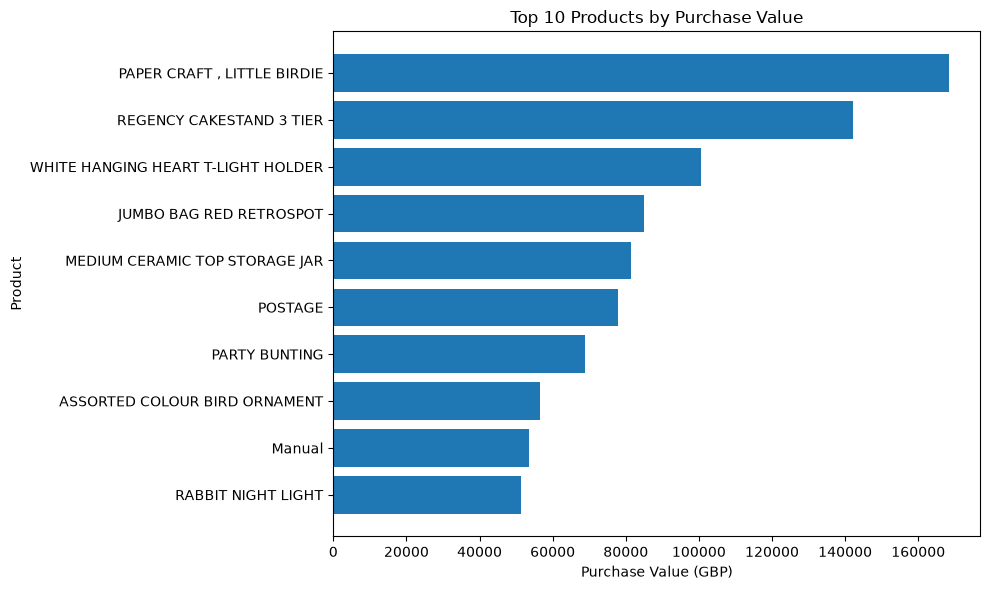

In [21]:
import matplotlib.pyplot as plt

top_products = (
    product_summary.head(10)
    .sort_values("PurchaseValue")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_products["Description"].astype(str),
    top_products["PurchaseValue"]
)

plt.title("Top 10 Products by Purchase Value")
plt.xlabel("Purchase Value (GBP)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

### Monthly Purchasing Trends

Monthly purchase value and transaction counts are examined to identify changes in purchasing activity over time. Average order value is calculated to help distinguish changes in transaction volume from changes in spending per transaction.

The source data ends on 9 December 2011, making December 2011 an incomplete month. Its monthly totals should not be compared directly with complete months.

Observed increases or decreases describe patterns in the available data. They do not, by themselves, establish the effects of promotions or recurring seasonality.

In [22]:
monthly_summary = (
    df.assign(
        Month=df["InvoiceDate"].dt.to_period("M")
    )
    .groupby("Month")
    .agg(
        PurchaseValue=("TotalPrice", "sum"),
        Transactions=("InvoiceNo", "nunique"),
        Customers=("CustomerID", "nunique")
    )
)

monthly_summary["AverageOrderValue"] = (
    monthly_summary["PurchaseValue"]
    / monthly_summary["Transactions"]
)

monthly_summary.round(2)

,PurchaseValue,Transactions,Customers,AverageOrderValue
Month,,,,
2010-12,570422.73,1400,885,407.44
2011-01,568101.31,987,741,575.58
2011-02,446084.92,997,758,447.43
2011-03,594081.76,1321,974,449.72
2011-04,468374.33,1149,856,407.64
2011-05,677355.15,1555,1056,435.60
2011-06,660046.05,1393,991,473.83
2011-07,598962.90,1331,949,450.01
2011-08,644051.04,1280,935,503.16


### Monthly Purchasing Trends

This analysis examines monthly purchasing activity using:
- **Purchase Value:** total purchase value recorded each month.
- **Transactions:** number of unique invoices each month.
- **Customers:** number of unique purchasing customers each month.
- **Average Order Value:** monthly purchase value divided by monthly
  transaction count.

Comparing purchase value with transaction counts helps assess whether
changes are accompanied by more transactions, higher average order
values, or both.

Monthly customer counts should not be added together to calculate the
total number of unique customers, since a customer can purchase in
multiple months.

#### Interpretation Limits

The dataset ends on 9 December 2011, so December 2011 is an incomplete
month. Its totals should not be compared directly with complete months
or interpreted as evidence of declining business performance.

All metrics describe positive purchases from identified customers in
the cleaned dataset, before deducting returns.

Observed trends alone do not establish the effects of marketing
campaigns or recurring seasonality. Additional data would be needed
to support those explanations.

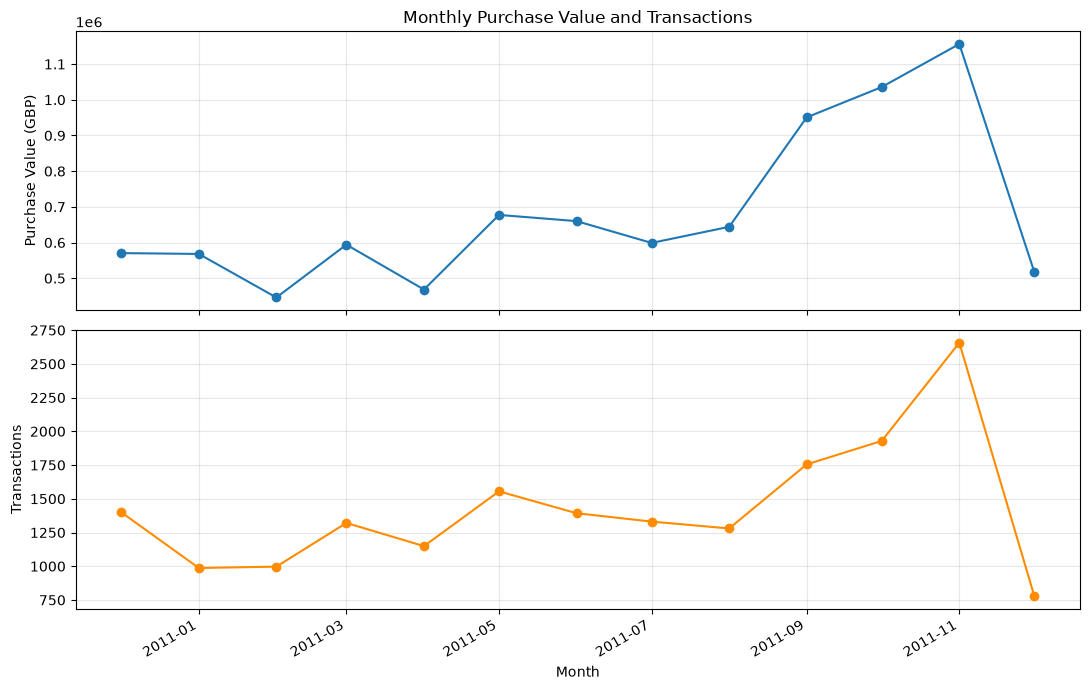

In [23]:
fig, axes = plt.subplots(
    2, 1, figsize=(11, 7), sharex=True
)

months = monthly_summary.index.to_timestamp()

axes[0].plot(
    months,
    monthly_summary["PurchaseValue"],
    marker="o"
)
axes[0].set_title("Monthly Purchase Value and Transactions")
axes[0].set_ylabel("Purchase Value (GBP)")

axes[1].plot(
    months,
    monthly_summary["Transactions"],
    marker="o",
    color="darkorange"
)
axes[1].set_ylabel("Transactions")
axes[1].set_xlabel("Month")

for ax in axes:
    ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## RFM Analysis

### Objective

RFM analysis summarizes purchasing behavior at the customer level using
three metrics:

- **Recency:** days since the customer's most recent purchase.
- **Frequency:** number of unique purchase invoices.
- **Monetary:** total purchase value during the observation period.

The transaction-level dataset is aggregated into one row per customer.
These features will support rule-based RFM segmentation and K-Means
clustering.

### Reference Date

The reference date is set to one calendar day after the latest valid
purchase date in the cleaned dataset. Recency is measured using calendar
dates so that transaction times do not affect the day count.

Using a reference date tied to the dataset makes the analysis reproducible
and appropriate for a historical snapshot.

### Interpretation and Scope

Lower Recency indicates a more recent purchase. Higher Frequency and
Monetary indicate more purchase occasions and greater observed spending.

Frequency counts unique invoices, not product rows or units purchased.
Monetary includes positive purchases from identified customers before
deducting returns.

The metrics reflect the available observation period. Customers first
observed near the end of the period have had less time to accumulate
purchases, which should be considered when interpreting their segments.

In [24]:
reference_date = (
    df["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

print("Tanggal acuan:", reference_date)

Tanggal acuan: 2011-12-10 00:00:00


In [25]:
rfm = (
    df.groupby("CustomerID")
    .agg(
        LastPurchase=("InvoiceDate", "max"),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("TotalPrice", "sum")
    )
)

rfm["Recency"] = (
    reference_date - rfm["LastPurchase"].dt.normalize()
).dt.days

rfm = rfm[
    ["Recency", "Frequency", "Monetary"]
].copy()

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,3,7,4310.00
12348,76,4,1797.24
12349,19,1,1757.55
12350,311,1,334.40


## RFM Analysis

### Objective

RFM analysis summarizes customer purchasing behavior using three metrics. The cleaned transaction data is aggregated into one row per customer to support RFM scoring and K-Means clustering.

| Metric | Definition | Interpretation |
|---|---|---|
| Recency | Calendar days since the most recent purchase | Lower values indicate more recent purchasing activity |
| Frequency | Number of unique purchase invoices during the observation period | Higher values indicate more purchase occasions |
| Monetary | Total purchase value during the observation period, in GBP | Higher values indicate greater observed spending |

### Calculation Method

The reference date is **10 December 2011**, one calendar day after the latest valid purchase date in the cleaned dataset.

For each customer:

- **Recency** is calculated as the reference date minus the last purchase date.
- **Frequency** counts unique InvoiceNo values rather than product rows or units.
- **Monetary** sums TotalPrice, calculated as Quantity × UnitPrice.

Dates are normalized to midnight before calculating Recency so that transaction times do not affect the calendar-day count.

### Scope and Validation

The resulting RFM table contains **4,338 unique customers**. Validation confirms that each customer has exactly one row, all three metrics are populated, Recency and Frequency are at least 1, and Monetary is positive.

The analysis includes positive purchases from identified customers after removing exact duplicates and invoices marked as cancellations. Monetary represents purchase value **before deducting returns**, not net revenue or profit.

These metrics describe the available observation period. Customers first observed near the end of that period have had less time to accumulate purchases. Recency alone does not identify when a customer first purchased.

In [26]:
assert len(rfm) == df["CustomerID"].nunique()
assert rfm.index.is_unique
assert rfm.notna().all().all()
assert rfm["Recency"].ge(1).all()
assert rfm["Frequency"].ge(1).all()
assert rfm["Monetary"].gt(0).all()

print("Pemeriksaan RFM lolos.")
print("Jumlah customer:", len(rfm))

rfm.describe().round(2)

Pemeriksaan RFM lolos.
Jumlah customer: 4338


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,93.06,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.75,5.00,1660.60
max,374.00,209.00,280206.02


### RFM Descriptive Statistics

The following statistics summarize purchasing behavior across the 4,338 customers.

| Statistic | Recency (days) | Frequency (invoices) | Monetary (GBP) |
|---|---:|---:|---:|
| Mean | 93.06 | 4.27 | 2,048.69 |
| Median | 51 | 2 | 668.57 |
| Standard deviation | 100.01 | 7.70 | 8,985.23 |
| Minimum | 1 | 1 | 3.75 |
| 25th percentile | 18 | 1 | 306.48 |
| 75th percentile | 142.75 | 5 | 1,660.60 |
| Maximum | 374 | 209 | 280,206.02 |

### Key Findings

**1. Customers vary substantially in how recently they purchased.**

Median Recency is 51 days, compared with a mean of 93.06 days. The higher mean suggests that customers with long periods since their last purchase pull the average upward. Recency ranges from 1 to 374 days.

This variation supports differentiating recently active customers from those who have not purchased for longer periods. However, inactivity does not establish churn without considering normal purchase cycles.

**2. Repeat purchasing is limited for many customers.**

Median Frequency is 2 invoices, while the mean is 4.27 and the maximum is 209. At least half of customers made no more than two purchases during the observation period, while some purchased much more frequently.

This suggests an opportunity to explore repeat-purchase strategies. Customer tenure should also be considered, since recently acquired customers have had less time to place additional orders.

**3. Customer spending appears strongly right-skewed.**

Mean Monetary is £2,048.69, substantially above the median of £668.57. The maximum is £280,206.02, compared with a 75th percentile of £1,660.60.

These statistics suggest that high-spending customers pull the mean upward, making the median a useful complementary measure of typical spending. Distribution plots and skewness calculations will be used to examine this pattern before clustering.

**4. Spending alone does not establish loyalty or current engagement.**

Customer 12346 illustrates this distinction:

- Recency: **326 days**
- Frequency: **1 invoice**
- Monetary: **£77,183.60**

The source invoice confirms the aggregated values. This customer has a large recorded purchase but low purchase frequency and a long period since the last purchase. A high Monetary value alone would therefore provide an incomplete picture.

The invoice check validates the aggregation; it does not establish retained revenue, because returns are excluded from the current Monetary calculation.

### Implications for Segmentation

The differences in purchasing recency, frequency, and value support examining multiple customer segments rather than relying on an average customer profile.

Frequency contains repeated values, including many customers with only one or two invoices. The scoring method should account for ties so that identical purchase frequencies receive consistent treatment.

The three features also have different scales and show signs of skewness. Distribution checks, potential transformations, and scaling will be evaluated before K-Means. Extreme values will be investigated rather than automatically removed.

## RFM Scoring

RFM scoring converts Recency, Frequency, and Monetary into scores
from 1 to 5 to support customer segmentation.

- **Recency:** lower values receive higher scores.
- **Frequency:** higher values receive higher scores.
- **Monetary:** higher values receive higher scores.

The 20th, 40th, 60th, and 80th percentiles of each metric are used
as scoring thresholds.

Customers with identical values receive identical scores, so score
groups may differ in size. Repeated thresholds may leave some score
levels unoccupied.

In [27]:
quantile_levels = [0.2, 0.4, 0.6, 0.8]

rfm_thresholds = rfm[
    ["Recency", "Frequency", "Monetary"]
].quantile(quantile_levels)

rfm_thresholds.round(2)

,Recency,Frequency,Monetary
0.2,13.8,1.0,249.34
0.4,33.0,2.0,487.41
0.6,72.0,3.0,933.35
0.8,180.0,6.0,2055.05


### Assigning RFM Scores

The calculated percentile thresholds are used to assign scores from 1 to 5. Recency scores are reversed because fewer days since the last purchase indicate more recent activity.

| Score | Recency (days) | Frequency (invoices) |
|---|---|---|
| 5 | 1–13 | 7 or more |
| 4 | 14–33 | 4–6 |
| 3 | 34–72 | 3 |
| 2 | 73–180 | 2 |
| 1 | 181 or more | 1 |

Monetary scores increase with spending, using percentile thresholds of approximately £249.34, £487.41, £933.35, and £2,055.05. Calculations use the original, unrounded thresholds.

Values equal to a threshold belong to the lower numeric interval before reversing the Recency score. Identical values receive identical scores, so groups are not required to contain equal numbers of customers.

The original RFM values are retained alongside their scores.

In [28]:
import numpy as np

rfm_scored = rfm.copy()

for metric, score_column in [
    ("Recency", "R_Score"),
    ("Frequency", "F_Score"),
    ("Monetary", "M_Score")
]:
    thresholds = rfm_thresholds[metric].to_numpy()

    scores = np.searchsorted(
        thresholds,
        rfm_scored[metric].to_numpy(),
        side="left"
    ) + 1

    if metric == "Recency":
        scores = 6 - scores

    rfm_scored[score_column] = scores

rfm_scored.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
CustomerID,,,,,,
12346,326,1,77183.60,1,1,5
12347,3,7,4310.00,5,5,5
12348,76,4,1797.24,2,4,4
12349,19,1,1757.55,4,1,4
12350,311,1,334.40,1,1,2


### Score Validation and Distribution

RFM scores are checked to ensure that every customer has a score between 1 and 5 for each metric. Customers with identical values must receive identical scores for that metric.

The number of customers at each score level is examined. Unequal group sizes are expected because customers with the same values are kept together, particularly for Frequency.

An RFM code combines the three scores in Recency–Frequency–Monetary order. For example, 115 indicates low Recency and Frequency scores but a high Monetary score.

The code is a categorical label, not a numeric total or a customer segment name.

In [29]:
score_columns = ["R_Score", "F_Score", "M_Score"]

# Periksa kelengkapan, rentang skor, dan jumlah customer
assert rfm_scored[score_columns].notna().all().all()
assert rfm_scored[score_columns].isin([1, 2, 3, 4, 5]).all().all()
assert rfm_scored.index.is_unique
assert len(rfm_scored) == len(rfm)

# Pastikan nilai yang sama mendapat skor yang sama
for metric, score_column in [
    ("Recency", "R_Score"),
    ("Frequency", "F_Score"),
    ("Monetary", "M_Score")
]:
    assert (
        rfm_scored.groupby(metric)[score_column]
        .nunique()
        .eq(1)
        .all()
    )

# Gabungkan skor menjadi label RFM
rfm_scored["RFM_Code"] = (
    rfm_scored["R_Score"].astype(str)
    + rfm_scored["F_Score"].astype(str)
    + rfm_scored["M_Score"].astype(str)
)

# Hitung jumlah customer pada setiap tingkat skor
score_distribution = pd.DataFrame({
    column: rfm_scored[column].value_counts()
    for column in score_columns
}).reindex([1, 2, 3, 4, 5]).fillna(0).astype(int)

score_distribution.index.name = "Score"

assert score_distribution.sum().eq(len(rfm_scored)).all()

print("Pemeriksaan skor lolos.")
display(score_distribution)
display(rfm_scored.head())

Pemeriksaan skor lolos.


,R_Score,F_Score,M_Score
Score,,,
1,861,1493,868
2,866,835,867
3,863,508,868
4,880,802,867
5,868,700,868


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Code
CustomerID,,,,,,,
12346,326,1,77183.60,1,1,5,115
12347,3,7,4310.00,5,5,5,555
12348,76,4,1797.24,2,4,4,244
12349,19,1,1757.55,4,1,4,414
12350,311,1,334.40,1,1,2,112


### Score Distribution Findings

All three score distributions contain 4,338 customers, and all five score levels are represented.

Recency and Monetary scores have approximately balanced group sizes. Frequency scores are less balanced because customers with identical purchase counts receive the same score.

A total of **1,493 customers (34.42%)** have a Frequency score of 1, corresponding to exactly one purchase invoice during the observation period. This group may include both recently observed customers and customers whose only purchase occurred much earlier.

A single purchase alone is therefore insufficient to label a customer as new.

### Identifying Newly Observed Customers

The first observed purchase date is added to distinguish customers who first purchased recently from those first observed earlier in the dataset.

**ObservedTenureDays** measures the calendar days between the first observed purchase and the reference date of 10 December 2011.

For this project, a customer is considered newly observed when their first recorded purchase occurred within the last 30 days. The New Customers segment will additionally require exactly one purchase invoice.

The 30-day window is an initial business rule, not a threshold learned from the data. It should be reviewed against typical purchase cycles before operational use.

Since purchases before the dataset began are unavailable, the first observed purchase does not necessarily represent the customer's first-ever purchase or acquisition date.

In [30]:
first_purchase = (
    df.groupby("CustomerID")["InvoiceDate"]
    .min()
)

rfm_scored["FirstPurchase"] = first_purchase

rfm_scored["ObservedTenureDays"] = (
    reference_date
    - rfm_scored["FirstPurchase"].dt.normalize()
).dt.days

new_customer_window = 30

rfm_scored["IsNewCustomer"] = (
    rfm_scored["ObservedTenureDays"].le(new_customer_window)
    & rfm_scored["Frequency"].eq(1)
)

assert rfm_scored["FirstPurchase"].notna().all()
assert (
    rfm_scored["ObservedTenureDays"] >= rfm_scored["Recency"]
).all()

print(
    "Customer dengan satu invoice dan pertama teramati "
    "dalam 30 hari terakhir:",
    rfm_scored["IsNewCustomer"].sum()
)

rfm_scored[
    [
        "Recency",
        "Frequency",
        "FirstPurchase",
        "ObservedTenureDays",
        "IsNewCustomer"
    ]
].head()

Customer dengan satu invoice dan pertama teramati dalam 30 hari terakhir: 207


,Recency,Frequency,FirstPurchase,ObservedTenureDays,IsNewCustomer
CustomerID,,,,,
12346,326,1,2011-01-18 10:01:00,326,False
12347,3,7,2010-12-07 14:57:00,368,False
12348,76,4,2010-12-16 19:09:00,359,False
12349,19,1,2011-11-21 09:51:00,19,True
12350,311,1,2011-02-02 16:01:00,311,False


## Rule-Based Customer Segmentation

Customers are assigned to eight segments using RFM scores and the previously defined new-customer flag.

The rules below are evaluated from top to bottom. Each customer receives the first matching segment, ensuring one segment per customer.

| Priority | Segment | Rule |
|---|---|---|
| 1 | New Customers | First observed within the last 30 days and exactly one invoice |
| 2 | Champions | R ≥ 4, F ≥ 4, and M ≥ 4 |
| 3 | Loyal Customers | R ≥ 3 and F ≥ 4, excluding customers already assigned |
| 4 | Potential Loyalist | R ≥ 3, excluding customers already assigned |
| 5 | Can't Lose Them | R ≤ 2 and either F = 5 or M = 5 |
| 6 | At Risk | R ≤ 2 and either F ≥ 3 or M ≥ 3, excluding customers already assigned |
| 7 | Lost | R = 1, excluding customers already assigned |
| 8 | Hibernating | R = 2, excluding customers already assigned |

R, F, and M refer to the corresponding scores, not the original metric values.

### Interpretation

Potential Loyalist is a development group of relatively recent purchasers who do not meet the preceding rules. It may include customers with only one invoice; the label indicates an opportunity to encourage repeat purchases rather than established loyalty.

Can't Lose Them prioritizes customers with high historical frequency or purchase value who have not purchased recently. High Monetary values should be interpreted in light of the exclusion of returns.

At Risk and Lost are operational labels based on observed inactivity, not confirmed churn outcomes. New Customers means newly observed within this dataset, not verified first-ever customers.

These rules are initial analytical choices rather than universal RFM standards. Their usefulness should be reviewed through segment profiling, purchase-cycle analysis, and campaign testing.

In [31]:
r = rfm_scored["R_Score"]
f = rfm_scored["F_Score"]
m = rfm_scored["M_Score"]

conditions = [
    rfm_scored["IsNewCustomer"],
    (r >= 4) & (f >= 4) & (m >= 4),
    (r >= 3) & (f >= 4),
    r >= 3,
    (r <= 2) & ((f == 5) | (m == 5)),
    (r <= 2) & ((f >= 3) | (m >= 3)),
    r == 1,
    r == 2
]

segment_names = [
    "New Customers",
    "Champions",
    "Loyal Customers",
    "Potential Loyalist",
    "Can't Lose Them",
    "At Risk",
    "Lost",
    "Hibernating"
]

rfm_scored["Segment"] = np.select(
    conditions,
    segment_names,
    default="Unclassified"
)

assert not rfm_scored["Segment"].eq("Unclassified").any()
assert (
    rfm_scored["Segment"].eq("New Customers")
    == rfm_scored["IsNewCustomer"]
).all()

segment_counts = (
    rfm_scored["Segment"]
    .value_counts()
    .reindex(segment_names, fill_value=0)
    .rename_axis("Segment")
    .to_frame("Customers")
)

segment_counts["CustomerSharePct"] = (
    segment_counts["Customers"] / len(rfm_scored) * 100
)

assert segment_counts["Customers"].sum() == len(rfm_scored)

display(segment_counts.round(2))

display(
    rfm_scored[
        ["Recency", "Frequency", "Monetary", "RFM_Code", "Segment"]
    ].head()
)

,Customers,CustomerSharePct
Segment,,
New Customers,207,4.77
Champions,911,21.00
Loyal Customers,381,8.78
Potential Loyalist,1112,25.63
Can't Lose Them,114,2.63
At Risk,659,15.19
Lost,617,14.22
Hibernating,337,7.77


,Recency,Frequency,Monetary,RFM_Code,Segment
CustomerID,,,,,
12346,326,1,77183.60,115,Can't Lose Them
12347,3,7,4310.00,555,Champions
12348,76,4,1797.24,244,At Risk
12349,19,1,1757.55,414,New Customers
12350,311,1,334.40,112,Lost


### Segment Distribution Findings

The rules assign all 4,338 customers to eight mutually exclusive segments.

Potential Loyalist is the largest segment, with **1,112 customers (25.63%)**, followed by Champions with **911 customers (21.00%)**. New Customers contains **207 customers (4.77%)**.

At Risk and Can't Lose Them together contain **773 customers (17.82%)**. These customers have relatively old last-purchase dates and meet the historical frequency or spending criteria specified in the segmentation rules.

These proportions describe the outcome of the chosen rules. They do not independently validate customer loyalty or confirm churn.

### Segment Profiling

Each segment is profiled using:

- Customer count and share of the customer population.
- Mean and median Recency, Frequency, and Monetary.
- Total purchase value and its share of overall purchase value.

Medians complement means because extreme customer values can influence averages. Comparing customer share with purchase

In [32]:
segment_profile = (
    rfm_scored.groupby("Segment")
    .agg(
        Customers=("Monetary", "size"),
        RecencyMean=("Recency", "mean"),
        RecencyMedian=("Recency", "median"),
        FrequencyMean=("Frequency", "mean"),
        FrequencyMedian=("Frequency", "median"),
        MonetaryMean=("Monetary", "mean"),
        MonetaryMedian=("Monetary", "median"),
        PurchaseValue=("Monetary", "sum")
    )
    .reindex(segment_names)
)

segment_profile["CustomerSharePct"] = (
    segment_profile["Customers"] / len(rfm_scored) * 100
)

segment_profile["PurchaseValueSharePct"] = (
    segment_profile["PurchaseValue"]
    / rfm_scored["Monetary"].sum()
    * 100
)

assert segment_profile["Customers"].sum() == len(rfm_scored)

assert np.isclose(
    segment_profile["PurchaseValue"].sum(),
    rfm_scored["Monetary"].sum()
)

display(
    segment_profile[
        [
            "Customers",
            "CustomerSharePct",
            "PurchaseValue",
            "PurchaseValueSharePct"
        ]
    ].round(2)
)

display(
    segment_profile[
        [
            "RecencyMean",
            "RecencyMedian",
            "FrequencyMean",
            "FrequencyMedian",
            "MonetaryMean",
            "MonetaryMedian"
        ]
    ].round(2)
)

,Customers,CustomerSharePct,PurchaseValue,PurchaseValueSharePct
Segment,,,,
New Customers,207,4.77,64415.10,0.72
Champions,911,21.00,5676143.38,63.87
Loyal Customers,381,8.78,823495.76,9.27
Potential Loyalist,1112,25.63,984141.92,11.07
Can't Lose Them,114,2.63,535807.96,6.03
At Risk,659,15.19,577008.66,6.49
Lost,617,14.22,142756.17,1.61
Hibernating,337,7.77,83439.94,0.94


,RecencyMean,RecencyMedian,FrequencyMean,FrequencyMedian,MonetaryMean,MonetaryMedian
Segment,,,,,,
New Customers,17.70,19.0,1.00,1.0,311.18,228.99
Champions,12.85,10.0,11.50,8.0,6230.67,2711.68
Loyal Customers,39.50,41.0,5.80,5.0,2161.41,1231.31
Potential Loyalist,36.56,36.0,2.00,2.0,885.02,528.21
Can't Lose Them,134.52,106.0,5.67,5.0,4700.07,2942.50
At Risk,159.21,137.0,2.50,2.0,875.58,752.60
Lost,276.97,270.0,1.13,1.0,231.37,217.20
Hibernating,123.09,123.0,1.25,1.0,247.60,243.36


### Segment Insights

**1. Purchase value is concentrated in Champions.**

Champions account for **911 customers (21.00%)** and **£5,676,143.38 (63.87%)** of total purchase value. Their median Recency is **10 days**, and median Frequency is **8 invoices**.

This segment combines recent purchasing activity, repeat purchases, and high spending. Its contribution supports prioritizing retention and service quality. However, high spending is partly expected because Monetary is included in the segment definition.

Mean customer spending is **£6,230.67**, compared with a median of **£2,711.68**, indicating substantial spending differences even within this segment.

**2. Potential Loyalist is the largest development group.**

Potential Loyalist contains **1,112 customers (25.63%)** and contributes **11.07%** of purchase value. Median Frequency is **2 invoices**, and median Recency is **36 days**.

This group provides a starting audience for repeat-purchase initiatives. Customers with one purchase should be distinguished from those who have already purchased multiple times when designing campaigns.

**3. Can't Lose Them warrants targeted reactivation assessment.**

This segment contains **114 customers (2.63%)**, contributing **£535,807.96 (6.03%)** of purchase value. Median Monetary is **£2,942.50**, while median Recency is **106 days**.

These customers have substantial historical value but have not purchased recently. Their purchase and return histories should be reviewed before prioritizing personalized reactivation.

**4. At Risk represents a broader reactivation audience.**

At Risk includes **659 customers (15.19%)** and contributes **6.49%** of purchase value. Median Recency is **137 days**, and median Monetary is **£752.60**.

Compared with Can't Lose Them, this group has lower typical spending. Campaigns should therefore test whether reactivation generates enough incremental value to justify their cost.

**5. New Customers should be evaluated through follow-up purchases.**

The **207 New Customers** contribute **0.72%** of purchase value and have a median Recency of **19 days**.

Their limited contribution should not be interpreted as low long-term potential: they have only recently been observed and have exactly one invoice by definition.

**6. Lost and Hibernating have low observed purchase value.**

Lost has **617 customers**, with median Recency of **270 days**. Hibernating has **337 customers**, with median Recency of **123 days**. Both have median Frequency of **1 invoice**.

Their low purchase frequency and spending support starting with limited-cost reactivation tests rather than assuming expensive incentives will be worthwhile.

### Interpretation Limits

These profiles describe a historical snapshot using the chosen segmentation rules. They do not establish customer profitability, confirmed churn, or campaign effectiveness.

Purchase value excludes the deduction of returns. Historical spending in inactive segments should not be described as forecast revenue loss.

### Initial Marketing Recommendations

The following actions are hypotheses to test, rather than proven outcomes of the segmentation.

| Segment | Proposed Action | Primary Evaluation Metric |
|---|---|---|
| Champions | Test loyalty benefits, early access, and relevant cross-selling | Repeat-purchase rate and incremental purchase value per customer |
| Loyal Customers | Recommend complementary products and relevant bundles | Purchase frequency and average order value |
| Potential Loyalist | Tailor follow-up offers to purchase history and prior order count | Repeat-purchase rate |
| New Customers | Provide onboarding, product guidance, and a relevant second-purchase prompt | Second-purchase rate within 30–60 days |
| Can't Lose Them | Review purchase and return history, then test personalized reactivation | Reactivation rate and incremental value after returns and campaign costs |
| At Risk | Test targeted reminders and selective incentives | Incremental reactivation rate and cost per incremental reactivated customer |
| Hibernating | Test limited-cost reminders based on previous purchases | Reactivation rate relative to campaign cost |
| Lost | Run a small win-back test before allocating a larger budget | Incremental reactivation and campaign profitability |

### Campaign Evaluation

Eligible customers should be randomly assigned to treatment and control groups within each segment. Outcomes should be measured over the same predefined follow-up period.

An increase in purchases among contacted customers alone does not demonstrate campaign impact, because some would have purchased without contact. Treatment–control comparisons help estimate incremental impact.

Campaign execution and evaluation require data beyond the current snapshot, including subsequent purchases, campaign assignment, returns, and costs. These recommendations have not yet been tested.

## Preparing RFM Features for K-Means

### Distribution and Skewness Assessment

The original Recency, Frequency, and Monetary values are examined before preprocessing. RFM scores and segment labels are excluded from the clustering features.

Histograms show how customer values are distributed, while skewness summarizes distribution asymmetry:

- Positive skewness indicates a longer right tail.
- Negative skewness indicates a longer left tail.
- Values near zero indicate approximate symmetry, but do not establish normality.

K-Means minimizes squared distances to cluster centers, so large feature scales and extreme values can strongly influence the results.

K-Means does not require normally distributed features. However, examining skewness helps assess whether a transformation could reduce the influence of long tails. Extreme values will not be removed solely because they are large.

,Mean,Median,Std,Min,Max,Skewness
Recency,93.06,51.00,100.01,1.00,374.00,1.25
Frequency,4.27,2.00,7.70,1.00,209.00,12.07
Monetary,2048.69,668.57,8985.23,3.75,280206.02,19.34


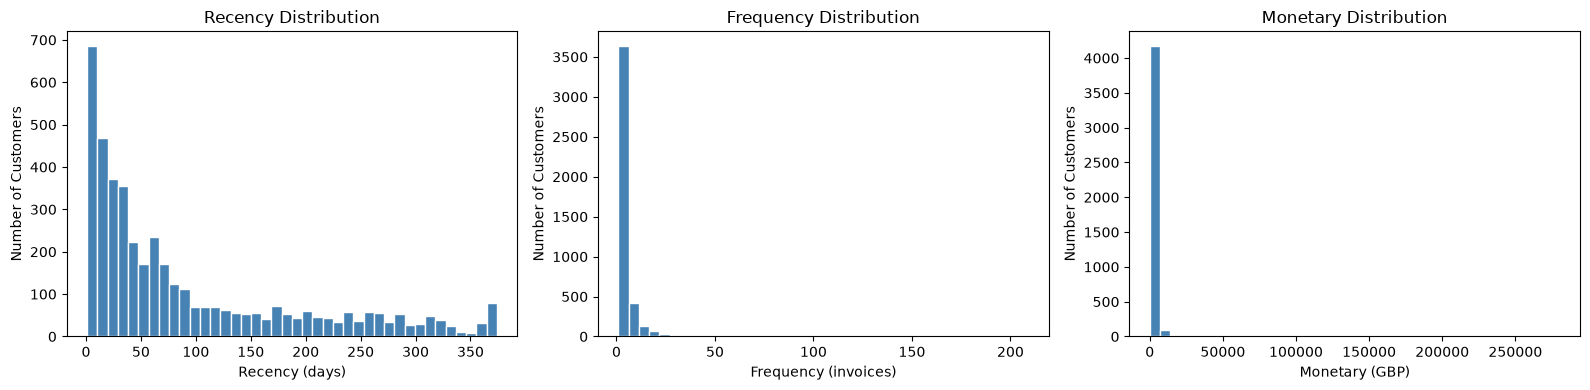

In [33]:
import matplotlib.pyplot as plt

rfm_features = rfm_scored[
    ["Recency", "Frequency", "Monetary"]
].copy()

distribution_summary = pd.DataFrame({
    "Mean": rfm_features.mean(),
    "Median": rfm_features.median(),
    "Std": rfm_features.std(),
    "Min": rfm_features.min(),
    "Max": rfm_features.max(),
    "Skewness": rfm_features.skew()
})

display(distribution_summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, metric in zip(axes, rfm_features.columns):
    ax.hist(
        rfm_features[metric],
        bins=40,
        color="steelblue",
        edgecolor="white"
    )
    ax.set_title(f"{metric} Distribution")
    ax.set_xlabel(
        f"{metric} (GBP)" if metric == "Monetary"
        else f"{metric} (days)" if metric == "Recency"
        else f"{metric} (invoices)"
    )
    ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Distribution Findings and Log Transformation

The original RFM features show positive skewness:

| Feature | Original Skewness |
|---|---:|
| Recency | 1.25 |
| Frequency | 12.07 |
| Monetary | 19.34 |

Frequency and Monetary have particularly long right tails. Most customers have relatively low values, while a small number have much higher purchase counts or spending.

A `log1p` transformation, defined as ln(1 + x), is evaluated for all three features. It compresses large values more strongly than small values while preserving their order.

Skewness and histograms are compared before and after transformation. The objective is to reduce the influence of long tails, not to force normal distributions, which K-Means does not require.

The transformation changes how differences between customers are represented. It is therefore a modeling choice whose usefulness must also be assessed through subsequent clustering results.

Original RFM values are retained for business interpretation and cluster profiling. No customers are removed in this step.

,OriginalSkewness,LogSkewness
Recency,1.25,-0.33
Frequency,12.07,1.21
Monetary,19.34,0.40


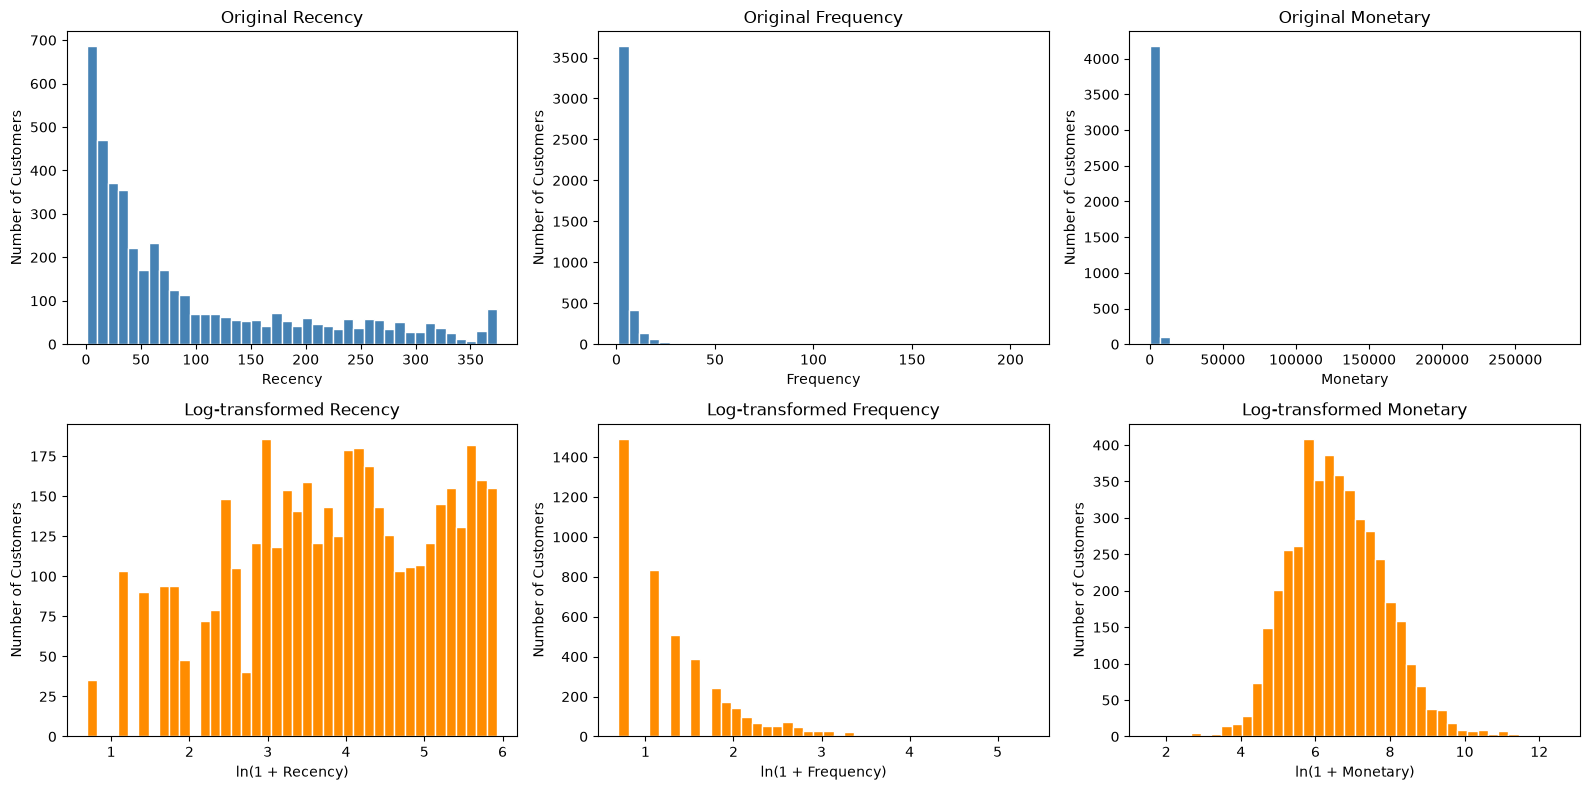

In [34]:
import numpy as np

rfm_log = np.log1p(rfm_features)

assert rfm_log.index.equals(rfm_features.index)
assert np.isfinite(rfm_log.to_numpy()).all()

skewness_comparison = pd.DataFrame({
    "OriginalSkewness": rfm_features.skew(),
    "LogSkewness": rfm_log.skew()
})

display(skewness_comparison.round(2))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for column_index, metric in enumerate(rfm_features.columns):
    axes[0, column_index].hist(
        rfm_features[metric],
        bins=40,
        color="steelblue",
        edgecolor="white"
    )
    axes[0, column_index].set_title(f"Original {metric}")
    axes[0, column_index].set_xlabel(metric)
    axes[0, column_index].set_ylabel("Number of Customers")

    axes[1, column_index].hist(
        rfm_log[metric],
        bins=40,
        color="darkorange",
        edgecolor="white"
    )
    axes[1, column_index].set_title(f"Log-transformed {metric}")
    axes[1, column_index].set_xlabel(f"ln(1 + {metric})")
    axes[1, column_index].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Log Transformation Results

The log1p transformation reduced absolute skewness across all three features:

| Feature | Original Skewness | Log-transformed Skewness |
|---|---:|---:|
| Recency | 1.25 | -0.33 |
| Frequency | 12.07 | 1.21 |
| Monetary | 19.34 | 0.40 |

Recency is now slightly left-skewed, while Monetary is approximately symmetric. Frequency remains right-skewed, with visible concentrations reflecting repeated integer purchase counts.

The transformed features are retained for the initial K-Means analysis. Reduced skewness supports this preprocessing choice but does not, by itself, establish that the resulting clusters will be useful.

### Feature Standardization

StandardScaler is applied to the log-transformed RFM features. For each feature, it subtracts the mean and divides by the population standard deviation.

This produces features with means approximately equal to zero and standard deviations approximately equal to one. Standardization prevents differences in feature variance from determining their relative influence on Euclidean distances.

Scaling does not remove remaining skewness or guarantee equal business importance. Original RFM values are retained for interpreting the resulting clusters.

The scaler is fitted to the current customer snapshot. If the fitted model is later used to assign new customers, the same transformation and fitted scaler must be reused.

In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = pd.DataFrame(
    scaler.fit_transform(rfm_log),
    index=rfm_log.index,
    columns=rfm_log.columns
)

scaling_summary = pd.DataFrame({
    "Mean": rfm_scaled.mean(),
    "Std": rfm_scaled.std(ddof=0),
    "Min": rfm_scaled.min(),
    "Max": rfm_scaled.max()
})

assert rfm_scaled.index.equals(rfm_log.index)
assert np.isfinite(rfm_scaled.to_numpy()).all()
assert np.allclose(rfm_scaled.mean(), 0, atol=1e-10)
assert np.allclose(rfm_scaled.std(ddof=0), 1)

display(scaling_summary.round(4))
display(rfm_scaled.head().round(3))

,Mean,Std,Min,Max
Recency,0.0,1.0,-2.4210,1.5837
Frequency,-0.0,1.0,-0.9552,5.8585
Monetary,-0.0,1.0,-3.9978,4.7324


,Recency,Frequency,Monetary
CustomerID,,,
12346,1.479,-0.955,3.708
12347,-1.891,1.074,1.415
12348,0.372,0.386,0.720
12349,-0.659,-0.955,0.702
12350,1.443,-0.955,-0.615


## Selecting the Number of Clusters

K-Means models are evaluated using the log-transformed and standardized RFM features.

Candidate cluster counts range from **2 to 10**. A one-cluster model is also fitted as a baseline for the inertia curve.

### Evaluation Metrics

**Inertia** measures the sum of squared distances between customers and their assigned cluster centers. Lower values indicate more compact clusters. However, inertia generally decreases as more clusters are added, so the lowest value alone does not identify the best cluster count.

The **Elbow Method** looks for a point where adding more clusters produces diminishing reductions in inertia.

**Silhouette Score** compares each customer's distance to customers in its own cluster with its distance to customers in the nearest alternative cluster. Scores range from -1 to 1:

- Higher positive values indicate better separation and cohesion.
- Values near zero indicate overlapping cluster boundaries.
- Negative values suggest that some customers may fit another cluster better.

Silhouette scores are calculated using all customers in the same transformed feature space used for clustering. The score is not defined for a single cluster.

Each model uses 20 initializations and a fixed random seed for reproducibility. The final cluster count will consider both metrics, cluster sizes, and business interpretability. It is not required to match the eight rule-based RFM segments.

,K,Inertia,Silhouette,SmallestCluster,LargestCluster
0,1,13014.0000,NaN,4338,4338
1,2,6476.5069,0.4325,1668,2670
2,3,4858.0785,0.3372,762,1876
3,4,3925.2745,0.3339,731,1541
4,5,3269.0748,0.3182,344,1167
5,6,2840.6540,0.3146,295,993
6,7,2532.9847,0.3103,230,892
7,8,2325.0754,0.3021,217,848
8,9,2145.8392,0.2816,212,663
9,10,1989.4049,0.2771,92,638


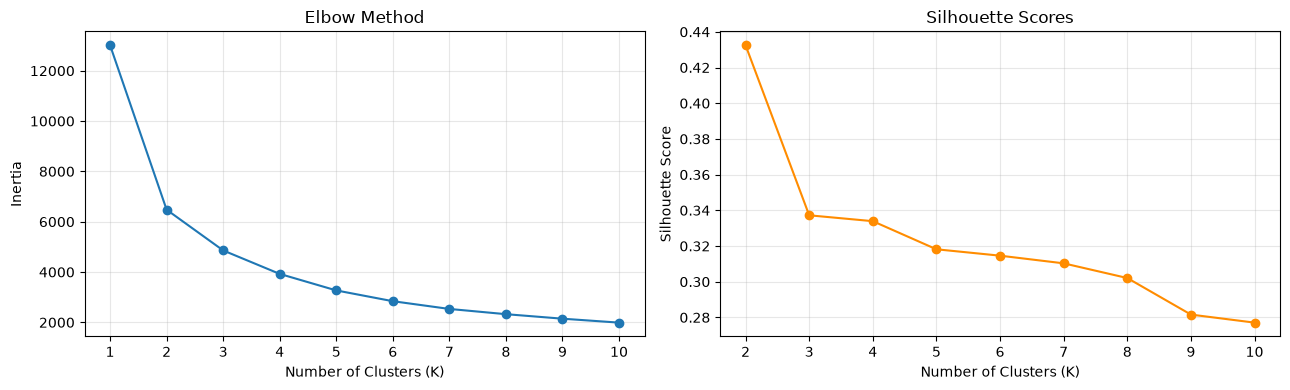

In [36]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

evaluation_results = []
candidate_models = {}

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    )

    labels = model.fit_predict(rfm_scaled)

    silhouette = (
        silhouette_score(rfm_scaled, labels)
        if k >= 2
        else np.nan
    )

    cluster_sizes = pd.Series(labels).value_counts()

    evaluation_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette,
        "SmallestCluster": cluster_sizes.min(),
        "LargestCluster": cluster_sizes.max()
    })

    candidate_models[k] = model

k_evaluation = pd.DataFrame(evaluation_results)

display(k_evaluation.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    k_evaluation["K"],
    k_evaluation["Inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(range(1, 11))

silhouette_results = k_evaluation.dropna(subset=["Silhouette"])

axes[1].plot(
    silhouette_results["K"],
    silhouette_results["Silhouette"],
    marker="o",
    color="darkorange"
)
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(range(2, 11))

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Cluster Evaluation Results

K = 2 achieves the highest Silhouette Score among the evaluated candidates, at **0.4325**. Scores decrease to **0.3372** for K = 3 and **0.3339** for K = 4, with further decreases for larger K values.

The inertia curve shows its largest reduction between K = 1 and K = 2, followed by progressively smaller improvements. It does not provide clear evidence that four clusters are optimal.

K = 2 is therefore the leading candidate based on the current internal evaluation. K = 3 and K = 4 are also inspected to determine whether additional groups provide useful business distinctions despite lower silhouette scores.

### Candidate Cluster Profiling

Candidate clusters are profiled using original RFM values so that Recency remains interpretable in days, Frequency in invoices, and Monetary in GBP.

Customer counts, median RFM values, mean spending, and purchase value contributions are compared. Medians describe typical customer behavior, while means and totals provide complementary information about spending.

Cluster identifiers are arbitrary labels. Cluster 0 in one model does not necessarily correspond to Cluster 0 in another model.

The final choice will consider separation, interpretability, and stability rather than assuming that more clusters are better.

In [37]:
candidate_profiles = {}

assert rfm_scaled.index.equals(rfm_scored.index)

for k in [2, 3, 4]:
    customer_data = rfm_scored[
        ["Recency", "Frequency", "Monetary"]
    ].copy()

    customer_data["Cluster"] = pd.Series(
        candidate_models[k].labels_,
        index=rfm_scaled.index
    )

    profile = (
        customer_data.groupby("Cluster")
        .agg(
            Customers=("Monetary", "size"),
            RecencyMedian=("Recency", "median"),
            FrequencyMedian=("Frequency", "median"),
            MonetaryMedian=("Monetary", "median"),
            MonetaryMean=("Monetary", "mean"),
            PurchaseValue=("Monetary", "sum")
        )
    )

    profile["CustomerSharePct"] = (
        profile["Customers"] / len(customer_data) * 100
    )

    profile["PurchaseValueSharePct"] = (
        profile["PurchaseValue"]
        / customer_data["Monetary"].sum()
        * 100
    )

    profile = profile[
        [
            "Customers",
            "CustomerSharePct",
            "RecencyMedian",
            "FrequencyMedian",
            "MonetaryMedian",
            "MonetaryMean",
            "PurchaseValueSharePct"
        ]
    ]

    candidate_profiles[k] = profile

    print(f"Cluster profile: K = {k}")
    display(profile.round(2))

Cluster profile: K = 2


,Customers,CustomerSharePct,RecencyMedian,FrequencyMedian,MonetaryMedian,MonetaryMean,PurchaseValueSharePct
Cluster,,,,,,,
0,1668,38.45,17.0,6.0,2058.17,4535.74,85.13
1,2670,61.55,96.0,1.0,362.01,494.98,14.87


Cluster profile: K = 3


,Customers,CustomerSharePct,RecencyMedian,FrequencyMedian,MonetaryMedian,MonetaryMean,PurchaseValueSharePct
Cluster,,,,,,,
0,1700,39.19,30.0,3.0,974.53,1257.13,24.05
1,1876,43.25,159.5,1.0,297.35,363.45,7.67
2,762,17.57,10.0,10.0,3718.22,7963.57,68.28


Cluster profile: K = 4


,Customers,CustomerSharePct,RecencyMedian,FrequencyMedian,MonetaryMedian,MonetaryMean,PurchaseValueSharePct
Cluster,,,,,,,
0,1177,27.13,54.0,4.0,1337.72,1793.44,23.75
1,889,20.49,20.0,2.0,418.40,493.28,4.93
2,731,16.85,9.0,10.0,3653.75,7923.97,65.18
3,1541,35.52,186.0,1.0,300.95,353.92,6.14


### Candidate Comparison

K = 2 provides the highest Silhouette Score (**0.4325**) and a broad distinction between customers with higher and lower purchasing activity. Its higher-value cluster contains **38.45% of customers** and contributes **85.13% of purchase value**.

K = 3 provides three profiles spanning relatively inactive, moderately active, and highly active customers.

K = 4 provides additional behavioral detail:

| Cluster | Customers | Median Recency | Median Frequency | Median Monetary |
|---|---:|---:|---:|---:|
| 0 | 1,177 | 54 days | 4 invoices | £1,337.72 |
| 1 | 889 | 20 days | 2 invoices | £418.40 |
| 2 | 731 | 9 days | 10 invoices | £3,653.75 |
| 3 | 1,541 | 186 days | 1 invoice | £300.95 |

These profiles could support different retention, repeat-purchase, and reactivation strategies. K = 4 is therefore considered a business-oriented candidate, while K = 2 remains the strongest candidate by silhouette.

The Silhouette Score for K = 4 is **0.3339**, indicating weaker separation than K = 2. More detailed profiles do not establish superior predictive performance or campaign effectiveness.

### Initialization Stability Check

K = 2, 3, and 4 are refitted using five alternative random seeds. Each run uses 20 initializations, consistent with the original evaluation.

Adjusted Rand Index (ARI) compares each run's assignments with the original seed-42 model for the same K. ARI accounts for arbitrary cluster label numbering:

- **1:** identical grouping.
- **Around 0:** agreement comparable to chance under the adjusted measure.
- **Negative values:** agreement below that reference.

This check evaluates sensitivity to initialization on the same dataset. It does not establish stability across different customer samples or time periods.

In [38]:
from sklearn.metrics import adjusted_rand_score

stability_results = []

for k in [2, 3, 4]:
    reference_labels = candidate_models[k].labels_

    for seed in [0, 7, 21, 99, 123]:
        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=20,
            random_state=seed
        )

        labels = model.fit_predict(rfm_scaled)

        stability_results.append({
            "K": k,
            "Seed": seed,
            "ARI": adjusted_rand_score(
                reference_labels,
                labels
            ),
            "Inertia": model.inertia_
        })

stability_results = pd.DataFrame(stability_results)

stability_summary = (
    stability_results.groupby("K")
    .agg(
        ARIMean=("ARI", "mean"),
        ARIMin=("ARI", "min"),
        ARIMax=("ARI", "max"),
        InertiaMin=("Inertia", "min"),
        InertiaMax=("Inertia", "max")
    )
)

display(stability_summary.round(4))

,ARIMean,ARIMin,ARIMax,InertiaMin,InertiaMax
K,,,,,
2,1.0000,1.0000,1.0000,6476.5052,6476.5069
3,0.9909,0.9822,0.9946,4858.0485,4858.2620
4,0.9434,0.9309,0.9559,3924.9315,3925.4487


### Final Cluster Count Selection

Initialization checks produced the following results:

| K | Mean ARI | Minimum ARI |
|---|---:|---:|
| 2 | 1.0000 | 1.0000 |
| 3 | 0.9909 | 0.9822 |
| 4 | 0.9434 | 0.9309 |

K = 2 has the strongest silhouette performance and initialization consistency. K = 4 also shows substantial agreement across the tested seeds, although some customer assignments change.

**K = 4 is selected for the marketing-oriented analysis** because its profiles distinguish active high-value customers, established repeat buyers, recent low-frequency buyers, and customers with older purchases and low engagement.

This choice trades some separation and stability for greater behavioral detail. It does not establish K = 4 as the statistically optimal solution or demonstrate improved campaign outcomes.

The original seed-42 model is retained for reproducibility and consistency with the reviewed profiles. Stability testing evaluates alternative initializations on the same snapshot, not changes across samples or time periods.

### Cluster Naming

Names describe the observed group profiles rather than verified customer status.

| Cluster | Name | Profile Basis |
|---|---|---|
| 0 | Established Repeat Buyers | Median Frequency of 4 invoices and Recency of 54 days |
| 1 | Recent Low-Frequency Buyers | Median Recency of 20 days and Frequency of 2 invoices |
| 2 | Active High-Value Buyers | Median Recency of 9 days, Frequency of 10 invoices, and Monetary of £3,653.75 |
| 3 | Inactive Low-Frequency Buyers | Median Recency of 186 days and Frequency of 1 invoice |

These are group-level descriptions, not conditions that every member must satisfy. “Recent” refers to the last purchase, and “inactive” does not establish confirmed churn.

In [39]:
selected_k = 4
final_model = candidate_models[selected_k]

assert rfm_scaled.index.equals(rfm_scored.index)

customer_segments = rfm_scored.copy()

customer_segments["Cluster"] = pd.Series(
    final_model.labels_,
    index=rfm_scaled.index
)

cluster_names = {
    0: "Established Repeat Buyers",
    1: "Recent Low-Frequency Buyers",
    2: "Active High-Value Buyers",
    3: "Inactive Low-Frequency Buyers"
}

customer_segments["ClusterName"] = (
    customer_segments["Cluster"].map(cluster_names)
)

assert customer_segments["ClusterName"].notna().all()
assert customer_segments.index.is_unique
assert len(customer_segments) == len(rfm_scored)

cluster_profile = (
    customer_segments.groupby(["Cluster", "ClusterName"])
    .agg(
        Customers=("Monetary", "size"),
        RecencyMean=("Recency", "mean"),
        RecencyMedian=("Recency", "median"),
        FrequencyMean=("Frequency", "mean"),
        FrequencyMedian=("Frequency", "median"),
        MonetaryMean=("Monetary", "mean"),
        MonetaryMedian=("Monetary", "median"),
        PurchaseValue=("Monetary", "sum")
    )
)

cluster_profile["CustomerSharePct"] = (
    cluster_profile["Customers"] / len(customer_segments) * 100
)

cluster_profile["PurchaseValueSharePct"] = (
    cluster_profile["PurchaseValue"]
    / customer_segments["Monetary"].sum()
    * 100
)

display(cluster_profile.round(2))

display(
    customer_segments[
        ["Recency", "Frequency", "Monetary", "Segment", "ClusterName"]
    ].head()
)

,,Customers,RecencyMean,RecencyMedian,FrequencyMean,FrequencyMedian,MonetaryMean,MonetaryMedian,PurchaseValue,CustomerSharePct,PurchaseValueSharePct
Cluster,ClusterName,,,,,,,,,,
0,Established Repeat Buyers,1177,68.03,54.0,4.12,4.0,1793.44,1337.72,2110874.60,27.13,23.75
1,Recent Low-Frequency Buyers,889,21.98,20.0,1.96,2.0,493.28,418.40,438524.82,20.49,4.93
2,Active High-Value Buyers,731,12.45,9.0,13.53,10.0,7923.97,3653.75,5792418.42,16.85,65.18
3,Inactive Low-Frequency Buyers,1541,191.42,186.0,1.33,1.0,353.92,300.95,545391.05,35.52,6.14


,Recency,Frequency,Monetary,Segment,ClusterName
CustomerID,,,,,
12346,326,1,77183.60,Can't Lose Them,Established Repeat Buyers
12347,3,7,4310.00,Champions,Active High-Value Buyers
12348,76,4,1797.24,At Risk,Established Repeat Buyers
12349,19,1,1757.55,New Customers,Recent Low-Frequency Buyers
12350,311,1,334.40,Lost,Inactive Low-Frequency Buyers


### Final Cluster Findings

Active High-Value Buyers contains **731 customers (16.85%)** and contributes **£5,792,418.42 (65.18%)** of observed purchase value. Median Recency is **9 days**, and median Frequency is **10 invoices**.

Established Repeat Buyers contains **1,177 customers (27.13%)** and contributes **23.75%** of purchase value. Its median Frequency is **4 invoices**, with median Recency of **54 days**.

Recent Low-Frequency Buyers contains **889 customers (20.49%)** and contributes **4.93%** of purchase value. Median Recency is **20 days**, and median Frequency is **2 invoices**.

Inactive Low-Frequency Buyers is the largest cluster, with **1,541 customers (35.52%)**, but contributes **6.14%** of purchase value. Median Recency is **186 days**, and median Frequency is **1 invoice**.

Cluster names summarize typical behavior rather than defining conditions every member must satisfy. All purchase value figures represent observed spending before deducting returns.

### Comparing RFM Segments and K-Means Clusters

A cross-tabulation compares the rule-based segments with the K-Means assignments.

Counts show how many customers belong to each segment–cluster combination. Row percentages show how customers within each RFM segment are distributed across the four clusters.

The comparison assesses overlap and differences between the two approaches. RFM segments are not ground-truth labels, so agreement is not interpreted as classification accuracy or independent validation. Both methods use the same underlying purchasing features.

ClusterName,Established Repeat Buyers,Recent Low-Frequency Buyers,Active High-Value Buyers,Inactive Low-Frequency Buyers
Segment,,,,
New Customers,0,207,0,0
Champions,213,13,685,0
Loyal Customers,283,60,37,1
Potential Loyalist,284,609,4,215
Can't Lose Them,107,0,5,2
At Risk,290,0,0,369
Lost,0,0,0,617
Hibernating,0,0,0,337


ClusterName,Established Repeat Buyers,Recent Low-Frequency Buyers,Active High-Value Buyers,Inactive Low-Frequency Buyers
Segment,,,,
New Customers,0.00,100.00,0.00,0.00
Champions,23.38,1.43,75.19,0.00
Loyal Customers,74.28,15.75,9.71,0.26
Potential Loyalist,25.54,54.77,0.36,19.33
Can't Lose Them,93.86,0.00,4.39,1.75
At Risk,44.01,0.00,0.00,55.99
Lost,0.00,0.00,0.00,100.00
Hibernating,0.00,0.00,0.00,100.00


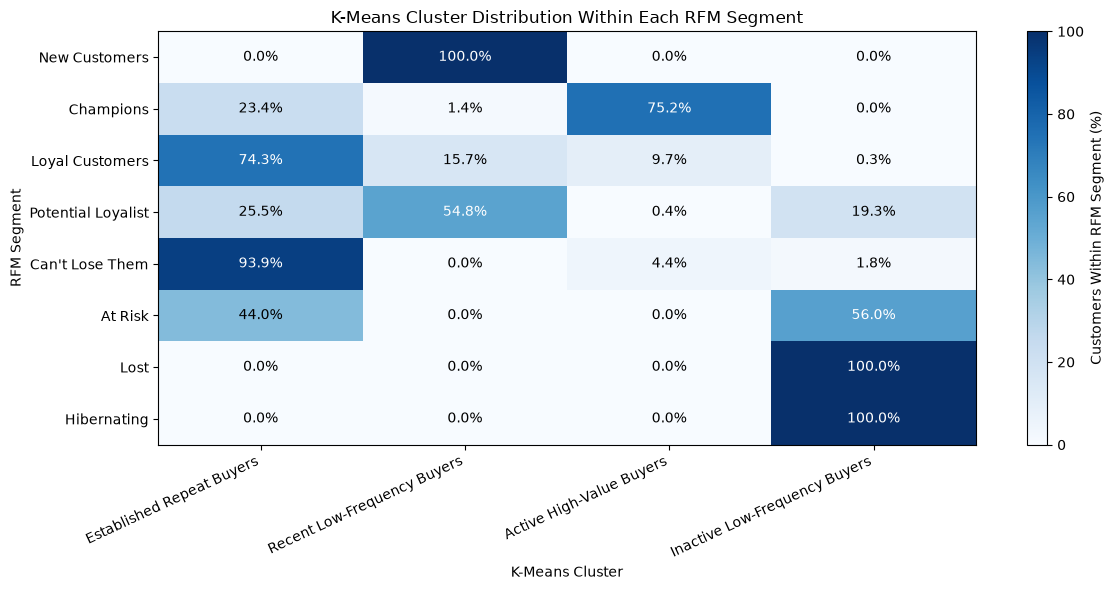

In [40]:
cluster_order = [
    cluster_names[i] for i in range(selected_k)
]

segment_cluster_counts = pd.crosstab(
    customer_segments["Segment"],
    customer_segments["ClusterName"]
).reindex(
    index=segment_names,
    columns=cluster_order,
    fill_value=0
)

segment_cluster_pct = (
    segment_cluster_counts
    .div(segment_cluster_counts.sum(axis=1), axis=0)
    * 100
)

assert (
    segment_cluster_counts.to_numpy().sum()
    == len(customer_segments)
)

assert np.allclose(
    segment_cluster_pct.sum(axis=1),
    100
)

display(segment_cluster_counts)
display(segment_cluster_pct.round(2))

fig, ax = plt.subplots(figsize=(12, 6))

heatmap = ax.imshow(
    segment_cluster_pct.to_numpy(),
    cmap="Blues",
    vmin=0,
    vmax=100,
    aspect="auto"
)

ax.set_xticks(range(selected_k))
ax.set_xticklabels(
    cluster_order,
    rotation=25,
    ha="right"
)

ax.set_yticks(range(len(segment_names)))
ax.set_yticklabels(segment_names)

for row in range(len(segment_names)):
    for column in range(selected_k):
        value = segment_cluster_pct.iloc[row, column]

        ax.text(
            column,
            row,
            f"{value:.1f}%",
            ha="center",
            va="center",
            color="white" if value >= 50 else "black"
        )

ax.set_title("K-Means Cluster Distribution Within Each RFM Segment")
ax.set_xlabel("K-Means Cluster")
ax.set_ylabel("RFM Segment")

fig.colorbar(
    heatmap,
    ax=ax,
    label="Customers Within RFM Segment (%)"
)

plt.tight_layout()
plt.show()

### RFM and K-Means Comparison Findings

All percentages below are calculated within each RFM segment.

**1. Most Champions belong to the active high-value cluster.**

Of the 911 Champions, **685 customers (75.19%)** belong to Active High-Value Buyers, while **213 (23.38%)** belong to Established Repeat Buyers.

This shows substantial overlap, but the two groups are not interchangeable. RFM applies score thresholds, whereas K-Means uses distances across transformed and standardized RFM values.

**2. Newly observed customers concentrate in the recent low-frequency cluster.**

All **207 New Customers** belong to Recent Low-Frequency Buyers. However, this cluster contains **889 customers** in total, so it should not be treated as a group consisting entirely of new customers.

The new-customer flag remains useful for separating onboarding audiences from other low-frequency purchasers.

**3. Lost and Hibernating share a broader cluster.**

All **617 Lost customers** and **337 Hibernating customers** belong to Inactive Low-Frequency Buyers.

K-Means groups these customers together, while the RFM rules preserve a distinction in inactivity duration that may help tailor reactivation timing.

**4. At Risk contains different customer profiles.**

At Risk is divided between Established Repeat Buyers (**290 customers; 44.01%**) and Inactive Low-Frequency Buyers (**369 customers; 55.99%**).

This split provides a basis for investigating different reactivation audiences. Their spending, purchase frequency, and return histories should be reviewed before assigning campaign budgets.

**5. Cluster names do not define every member's behavior.**

Potential Loyalist includes **215 customers (19.33%)** assigned to Inactive Low-Frequency Buyers, despite the segment requiring a Recency score of at least 3.

Similarly, **107 Can't Lose Them customers (93.86%)** belong to Established Repeat Buyers, although their RFM segment indicates older last-purchase dates.

These differences demonstrate why cluster names should be interpreted as summaries rather than individual eligibility rules.

### Practical Use

K-Means provides broad behavioral groups, while RFM rules provide explicit targeting criteria. Campaign audiences can combine both assignments with original RFM values.

The overlap is descriptive, not an accuracy measure or independent validation: both methods rely on the same underlying purchasing data.

### Cluster-Based Marketing Recommendations

| Cluster | Proposed Strategy | Targeting Refinement | Evaluation |
|---|---|---|---|
| Active High-Value Buyers | Test loyalty benefits, personalized cross-selling, and early access | Check individual Recency and RFM segment before inclusion; separate customers flagged for reactivation | Incremental repeat purchases and purchase value |
| Established Repeat Buyers | Encourage continued purchasing through relevant recommendations; test reactivation for less recent buyers | Separate Champions and Loyal Customers from At Risk and Can't Lose Them | Incremental repeat-purchase or reactivation rate by audience |
| Recent Low-Frequency Buyers | Encourage the next purchase through product guidance and relevant follow-up offers | Use IsNewCustomer to distinguish onboarding from other repeat-purchase campaigns | Second-purchase rate for new customers; repeat-purchase rate for others |
| Inactive Low-Frequency Buyers | Test limited-cost reactivation for customers with older last-purchase dates | Verify individual Recency; treat relatively recent Potential Loyalist members separately | Incremental reactivation relative to campaign cost |

### Business Priorities

1. **Protect the high-value customer base.** Active High-Value Buyers represents 16.85% of customers and contributes 65.18% of observed purchase value.
2. **Develop repeat purchasing.** Recent Low-Frequency Buyers provides an audience for testing next-purchase strategies, with separate treatment for newly observed customers.
3. **Target reactivation selectively.** Use individual inactivity, historical spending, and return information to refine audiences rather than contacting every member of a broadly named cluster.

These actions are testable recommendations, not demonstrated business outcomes. Randomized treatment and control groups should be used to estimate incremental campaign impact. Profitability evaluation additionally requires return, product cost, and campaign cost data.

In [41]:
from pathlib import Path

export_dir = Path("outputs")
export_dir.mkdir(parents=True, exist_ok=True)

customers_export = customer_segments.reset_index().copy()

customers_export["CustomerID"] = (
    customers_export["CustomerID"].astype("string")
)

customers_export["SnapshotDate"] = reference_date

transactions_export = df[
    [
        "CustomerID",
        "InvoiceNo",
        "InvoiceDate",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "TotalPrice",
        "Country"
    ]
].copy()

transactions_export["CustomerID"] = (
    transactions_export["CustomerID"].astype("string")
)

transactions_export["InvoiceNo"] = (
    transactions_export["InvoiceNo"].astype("string")
)

transactions_export["StockCode"] = (
    transactions_export["StockCode"].astype("string")
)

transactions_export["InvoiceDay"] = (
    transactions_export["InvoiceDate"].dt.normalize()
)

assert customers_export["CustomerID"].is_unique
assert customers_export["CustomerID"].notna().all()

assert transactions_export["CustomerID"].isin(
    customers_export["CustomerID"]
).all()

assert np.isclose(
    customers_export["Monetary"].sum(),
    transactions_export["TotalPrice"].sum()
)

customer_totals = (
    transactions_export.groupby("CustomerID")["TotalPrice"]
    .sum()
)

expected_totals = (
    customers_export.set_index("CustomerID")["Monetary"]
    .reindex(customer_totals.index)
)

assert np.allclose(
    customer_totals.to_numpy(),
    expected_totals.to_numpy()
)

customers_export.to_csv(
    export_dir / "customers.csv",
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d %H:%M:%S"
)

transactions_export.to_csv(
    export_dir / "transactions.csv",
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d %H:%M:%S"
)

print("Pemeriksaan ekspor lolos.")
print("Jumlah customer:", len(customers_export))
print("Jumlah baris item pembelian:", len(transactions_export))
print("Lokasi file:", export_dir.resolve())

Pemeriksaan ekspor lolos.
Jumlah customer: 4338
Jumlah baris item pembelian: 392692
Lokasi file: /Users/user/Project/Customer Segmentation/outputs
